In [6]:
import os
from pathlib import Path
from dotenv import load_dotenv

BASE_DIR = Path(
    "/home/abi/vison-model/"
    "Vision-Based Product Attribution and BOM Mapping"
)

ENV_PATH = BASE_DIR / ".env"

if not ENV_PATH.exists():
    raise FileNotFoundError(f".env file not found: {ENV_PATH}")

load_dotenv(ENV_PATH, override=False)

required_vars = [
    "BEDROCK_BASE_URL",
    "BEDROCK_API_KEY",
    "AWS_REGION",
]

for name in required_vars:
    value = os.getenv(name)
    print(f"{name}: {'Loaded' if value else 'MISSING'}")

if not os.getenv("BEDROCK_API_KEY"):
    raise EnvironmentError("BEDROCK_API_KEY is missing from the environment.")

print("Environment loading complete.")

BEDROCK_BASE_URL: Loaded
BEDROCK_API_KEY: Loaded
AWS_REGION: Loaded
Environment loading complete.


In [7]:
import os
import boto3

REGION = os.getenv("AWS_REGION", "us-east-1")

MODEL_ID = "global.anthropic.claude-haiku-5-5"

# Configure Bedrock bearer-token authentication
os.environ["AWS_BEARER_TOKEN_BEDROCK"] = os.environ["BEDROCK_API_KEY"]

bedrock = boto3.client(
    "bedrock-runtime",
    region_name=REGION
)

print("Bedrock client initialized.")
print("Region:", REGION)
print("Model:", MODEL_ID)

Bedrock client initialized.
Region: us-east-1
Model: global.anthropic.claude-haiku-5-5


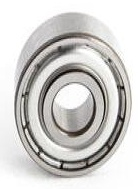

```json
{
  "part_type": {
    "value": "Deep groove ball bearing (shielded type, likely with metal shields)",
    "confidence": "medium",
    "evidence": "The part is a cylindrical ring with a central bore and an outer race. A metallic shield or cover appears on the visible face, which is typical of shielded deep groove ball bearings. The shield type and bearing series cannot be confirmed from this view."
  },
  "geometry": {
    "value": "Cylindrical annular ring (toroidal outer profile with a straight through-bore)",
    "confidence": "high",
    "evidence": "Visible outer circumferential surface, a central through-bore, and concentric inner and outer rings. The face shows a stepped profile between the bore and outer diameter."
  },
  "material": {
    "value": "Appears to be metallic, likely steel (interpretation)",
    "confidence": "low",
    "evidence": "The surfaces have a uniform silver metallic finish and specular highlights consistent with polished or plated steel. Image res

In [12]:
import json
import base64
import mimetypes
from pathlib import Path
from IPython.display import display, Markdown
from PIL import Image

# Select a mechanical-part image
IMAGE_PATH = (
    BASE_DIR
    / "data/combined/crops/bearing/CROP-000344.jpg"
)

if not IMAGE_PATH.exists():
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

display(Image.open(IMAGE_PATH))

# Prepare the image
mime_type, _ = mimetypes.guess_type(str(IMAGE_PATH))

if mime_type not in {"image/jpeg", "image/png", "image/webp"}:
    raise ValueError(f"Unsupported image format: {mime_type}")

image_format = mime_type.split("/")[1]

with open(IMAGE_PATH, "rb") as f:
    image_bytes = f.read()

prompt = """
You are a mechanical engineering visual inspection assistant.

Analyze the supplied image and extract mechanical-part attributes.

Return ONLY valid JSON using this schema:

{
  "part_type": {
    "value": null,
    "confidence": "low",
    "evidence": ""
  },
  "geometry": {
    "value": null,
    "confidence": "low",
    "evidence": ""
  },
  "material": {
    "value": null,
    "confidence": "low",
    "evidence": ""
  },
  "dimensions": {
    "value": null,
    "confidence": "low",
    "evidence": ""
  },
  "manufacturer": {
    "value": null,
    "confidence": "low",
    "evidence": ""
  },
  "manufacturer_part_number": {
    "value": null,
    "confidence": "low",
    "evidence": ""
  },
  "visible_markings": [],
  "physical_features": [],
  "additional_observations": [],
  "unresolved_attributes": []
}

Rules:
- Use only high, medium, or low for confidence.
- Do not invent dimensions or infer exact measurements from pixels.
- Do not guess manufacturers or part numbers.
- Use null when an attribute cannot be determined.
- Describe visible geometry, holes, grooves, threads, teeth,
  surface features, and other relevant characteristics.
- Report visible text only when it can actually be read.
- Distinguish visual observations from interpretations.
- Treat this as a single image, not a complete product specification.
"""

response = bedrock.converse(
    modelId=MODEL_ID,
    messages=[
        {
            "role": "user",
            "content": [
                {"text": prompt},
                {
                    "image": {
                        "format": image_format,
                        "source": {"bytes": image_bytes}
                    }
                }
            ]
        }
    ],
    inferenceConfig={
        "maxTokens": 1500,
        
    }
)

result_text = "".join(
    block["text"]
    for block in response["output"]["message"]["content"]
    if "text" in block
)

print(result_text)

try:
    attributes = json.loads(result_text)
    print("\nJSON parsing successful.")
except json.JSONDecodeError:
    print("\nResponse is not valid JSON; inspect the raw output.")